# Frequency Domain Linear Prediction (FDLP) Implementation
This notebook implements **Frequency Domain Linear Prediction (FDLP)** based on the PhD dissertation:
*"Signal Analysis Using Autoregressive Models of Amplitude Modulation"* by Sriram Ganapathy (Johns Hopkins University, 2012).

### Key Architectural Steps:
1. **Full-Band DCT:** Compute Type-I Discrete Cosine Transform over long temporal windows (e.g. 1–2 seconds).
2. **Sub-Band Decomposition:** Apply Gaussian-shaped Mel frequency filter weighting across DCT coefficients.
3. **Autoregressive (AR) Modeling:** Apply linear prediction on the sub-band DCT coefficients to model the temporal **Hilbert Envelope**.
4. **Gain Normalization:** Set gain $G = 1$ in narrow sub-bands to remove room reverberation and convolutive channel artifacts.
5. **Short-Term Integration:** Compute sub-band envelope energy in 25 ms windows with 10 ms hop (100 Hz frame rate).
6. **Comparison:** Compare the resulting FDLP Spectrogram against conventional Mel Spectrogram on `audio.wav`.


In [1]:
import os
import glob
import math
import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import detrend
from scipy.signal.windows import hamming
from scipy.fftpack import dct
import librosa
import librosa.display

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
def hz2mel(f, htk=False):
    """
    Convert frequencies (in Hz) to mel scale.
    """
    f = np.asanyarray(f)
    if htk:
        return 2595 * np.log10(1 + f / 700.0)
    else:
        f_0 = 0.0
        f_sp = 200.0 / 3.0
        brkfrq = 1000.0
        brkpt = (brkfrq - f_0) / f_sp
        logstep = np.exp(np.log(6.4) / 27.0)

        z = np.zeros_like(f)
        linpts = f < brkfrq
        z[linpts] = (f[linpts] - f_0) / f_sp
        z[~linpts] = brkpt + np.log(f[~linpts] / brkfrq) / np.log(logstep)
        return z

def melweights_mod(flen, sr, nbands=36, dB=48):
    """
    Generate Gaussian Mel filter weights for FDLP across DCT frequency bins.
    """
    nfreqs = flen
    maxmel = hz2mel(sr / 2)
    step = maxmel / (nbands - 1)

    freqs_hz = np.linspace(0, sr / 2, nfreqs)
    bin_mel = hz2mel(freqs_hz)
    lin = 10 ** (-dB / 20)

    wts = []
    idx = np.zeros((nbands, 2), dtype=int)

    for i in range(nbands):
        f_mel_mid = i * step
        weight = np.exp(-0.5 * ((bin_mel - f_mel_mid) ** 2))
        valid_idx = np.where(weight >= lin)[0]
        if len(valid_idx) == 0:
            valid_idx = np.array([0, 0])
        idx[i, 0] = valid_idx[0]
        idx[i, 1] = valid_idx[-1]
        wts.append(weight[valid_idx])

    return wts, idx

def bandlimit_wtsremoval(wts, idx, flen, sr, minfreq=0, maxfreq=8000):
    """
    Band-limit the weights by keeping only sub-bands whose center peaks fall within [minfreq, maxfreq].
    """
    new_wts = []
    new_idx = []

    for i in range(len(wts)):
        tmpx = np.zeros(flen)
        start, end = idx[i]
        tmpx[start:end+1] = wts[i]

        peak_idx = np.argmax(tmpx)
        peak_freq = peak_idx * (sr / 2) / flen

        if minfreq <= peak_freq <= maxfreq:
            new_wts.append(wts[i])
            new_idx.append([start, end])

    return new_wts, np.array(new_idx, dtype=int)


In [3]:
def ditherit_2(x, db=None, dtype=None, amp=None, mode=None, **kwargs):
    """
    Dithers a signal by adding low-level random noise.
    """
    if db is None:
        db = amp if amp is not None else -1
    if dtype is None:
        dtype = mode if mode is not None else 'db'

    x = np.asarray(x, dtype=float)
    if dtype.lower() == 'db':
        noise = (10 ** (db / 20)) * np.random.randn(*x.shape)
        return x + noise
    elif dtype.lower() == 'bit':
        noise = np.round(2 * db * np.random.rand(*x.shape) - db)
        return x + noise
    return x

def enframe(x, win, inc=None):
    """
    Split a 1D signal into overlapping frames.
    """
    x = np.asarray(x).flatten()
    nx = len(x)
    frame_len = int(win) if np.isscalar(win) else len(win)

    if inc is None:
        inc = frame_len
    inc = int(inc)

    nf = int(np.floor((nx - frame_len + inc) / inc))
    f = np.zeros((nf, frame_len))

    for i in range(nf):
        start = i * inc
        f[i, :] = x[start : start + frame_len]

    if not np.isscalar(win) and len(win) > 1:
        w = win.flatten()
        f = f * w[np.newaxis, :]

    return f

def frame_new(x, FRAME, R):
    """
    Frame input signal into overlapping blocks of length FRAME with overlap R.
    """
    x = np.asarray(x).flatten()
    NB_FR = int(np.ceil((len(x) - FRAME) / (FRAME - R) + 1))
    req_len = int(FRAME + (NB_FR - 1) * (FRAME - R))
    add_samp = req_len - len(x)

    if add_samp > 0:
        pad = np.zeros(add_samp)
        pad = ditherit_2(pad, amp=1.0, mode='bit')
        x = np.concatenate((x, pad))

    if NB_FR > 0:
        xtr = enframe(x, FRAME, FRAME - R).T
    else:
        raise ValueError("Cannot create frames — check frame and overlap parameters.")

    return xtr, add_samp

def frame_signal(x, frame_len, overlap):
    """
    Creates overlapping frames of a 1D envelope (equivalent to MATLAB buffer).
    """
    step = frame_len - overlap
    num_frames = int(np.floor((len(x) - overlap) / step))
    frames = np.zeros((num_frames, frame_len))
    for i in range(num_frames):
        start = i * step
        frames[i, :] = x[start : start + frame_len]
    return frames


In [4]:
def arfit_2(v, pmin, pmax=None, selector=None):
    """
    Autoregressive model fitting using Least Squares regression (ARFIT formulation).
    """
    p = int(pmin)
    v = np.asarray(v, dtype=float)
    if v.ndim == 1:
        v = v.reshape(-1, 1)

    n, m = v.shape
    p = min(p, max(1, (n - 2) // m))

    Z = np.zeros((n - p, m * p))
    for j in range(p):
        Z[:, j * m : (j + 1) * m] = v[p - j - 1 : n - j - 1, :]

    Y = v[p:, :]
    coef, _, _, _ = np.linalg.lstsq(Z, Y, rcond=None)
    E = Y - Z @ coef

    w = np.zeros((1, m))
    A = coef.T
    dof = max(1, (n - p) - (m * p))
    C = (E.T @ E) / dof

    detC = np.linalg.det(C)
    Cnorm = C if detC <= 0 else C / (detC ** (1.0 / m))
    return w, A, C, Cnorm

def estimate_mvar_ARFIT_fast_2(AModel, Q, N, E=None, do_gain_norm=True):
    """
    Evaluates the all-pole envelope in the dual time domain from the AR coefficients.
    """
    d = Q.shape[0]
    p = AModel.shape[1] // d

    I = np.eye(d)
    AR = np.hstack([I, -AModel])
    AR_mod = np.reshape(AR, (d * d, p + 1), order='F')

    A_fft = np.fft.fft(AR_mod, n=2 * N - 1, axis=1)
    A_fft = A_fft[:, :N]

    x = np.zeros((d, N))
    for n in range(N):
        H = np.linalg.inv(A_fft[:, n].reshape((d, d), order='F'))
        x[:, n] = 2 * np.real(np.diag(H @ Q @ H.conj().T))

    if do_gain_norm:
        # Proposition 3: Gain normalization suppresses convolutive artifacts
        denom = np.sum(x, axis=1, keepdims=True)
        denom[denom == 0] = 1e-12
        x = x / denom

    return x

def env_hlpc_vAR(Y, nAR, N, do_gain_norm=True):
    """
    Extracts sub-band Hilbert envelope using all-pole modeling.
    """
    Y = np.atleast_2d(Y)
    if Y.shape[1] > Y.shape[0]:
        Y = Y.T

    n_channels, n_samples = Y.shape
    E = np.sum(Y**2, axis=0)

    w, A, C, Cnorm = arfit_2(Y, nAR, nAR, 'zero')
    ENV = estimate_mvar_ARFIT_fast_2(A, C, N, E, do_gain_norm)
    return ENV

def fdlpfit_full_sig_vAR(x, sr=16000, dB=48, do_gain_norm=False, band_decom='mel', npts=None, nochan=1):
    """
    Decomposes the DCT of the signal into sub-bands and computes all-pole Hilbert envelopes.
    """
    x = np.atleast_2d(x)
    nchan, flen = x.shape

    # 1. Discrete Cosine Transform (DCT)
    x_dct = dct(x, axis=1, norm='ortho')

    # 2. Sub-band filter weights
    wts, idx = melweights_mod(flen, sr, nbands=36, dB=dB)
    factor = 300
    fp = max(round(flen / factor), 1)
    wts, idx = bandlimit_wtsremoval(wts, idx, flen, sr, 0, sr / 2)

    nb = len(idx)
    if npts is None:
        npts = flen

    ENVall = np.zeros((nb * nochan, npts))
    K = 1

    for I in range(0, nb, K):
        currBands = list(range(I, min(I + K, nb)))
        arrCurrBands = []
        lenCurrBands = min([idx[b][1] - idx[b][0] for b in currBands])

        for b in currBands:
            temp = x_dct[:, idx[b][0] : idx[b][1] + 1] * wts[b][np.newaxis, :]
            temp = temp[:, :lenCurrBands]
            arrCurrBands.append(temp)

        arrCurrBands = np.vstack(arrCurrBands)
        tempENV = env_hlpc_vAR(arrCurrBands, fp, npts, do_gain_norm)
        start_idx = (I // K) * K * nochan
        ENVall[start_idx : start_idx + K * nochan, :] = tempENV

    return ENVall.T

def fdlp_env_comp_100hz(x, sr=16000, num_ceps=14, flag_delta=0, do_gain_norm=0, nochan=1):
    """
    Extracts short-term integrated sub-band energy from the FDLP envelope (100 Hz frame rate).
    """
    x = np.asarray(x).flatten()
    dB = 48
    flen_orig = int(0.025 * sr)
    fhop_orig = int(0.010 * sr)
    fnum = int(np.floor((len(x) - flen_orig) / fhop_orig) + 1)
    send = (fnum - 1) * fhop_orig + flen_orig

    factor = 40
    flen = int(np.floor(0.025 * sr / factor))
    fhop = int(np.floor(0.010 * sr / factor))
    fdlplen = len(x)
    npts = int(np.floor(fdlplen / factor))

    ENV = fdlpfit_full_sig_vAR(x, sr, dB, do_gain_norm, 'mel', npts, nochan)
    ENV = np.array(ENV).T
    nb = ENV.shape[0]
    fdlp_spec = ENV[:, :int(np.floor(send / factor))]

    wind = hamming(flen, sym=False)
    test_frames = frame_signal(fdlp_spec[0, :], flen, flen - fhop)
    actual_fnum = test_frames.shape[0]
    bandenergy = np.zeros((nb, actual_fnum))

    for band in range(nb):
        banddata = frame_signal(fdlp_spec[band, :], flen, flen - fhop)
        bandenergy[band, :] = np.dot(banddata, wind)

    return bandenergy ** 0.10


In [5]:
def generate_env_feats(A, sr, nochan=1):
    """
    Splits multi-second audio into 2-second FDLP windows and extracts envelopes.
    """
    do_gain_norm = True
    ceps = 14
    flen = int(0.025 * sr)
    fhop = int(0.010 * sr)
    total_samples = A.shape[1]

    fnum = int(np.floor((total_samples - flen) / fhop) + 1)
    send = int((fnum - 1) * fhop + flen)
    A = A[:, :send]

    fdlpwin = min(2 * sr, send)
    fdlpolap = int(0.020 * sr)

    X = []
    add_samp = None
    for j in range(nochan):
        x_frames, add_samp = frame_new(A[j, :], fdlpwin, fdlpolap)
        X.append(x_frames)
    X = np.stack(X, axis=0)

    cepstra = []
    for i in range(X.shape[2]):
        x = X[:, :, i]
        if i == X.shape[2] - 1 and add_samp:
            x = x[:, :-add_samp]
        x = detrend(x, axis=-1, type='constant')

        if x.shape[1] < 400:
            continue

        temp = fdlp_env_comp_100hz(x, sr, ceps, True, do_gain_norm, nochan)
        cepstra.append(temp)

    if len(cepstra) == 0:
        return np.zeros((ceps, 1))

    return np.concatenate(cepstra, axis=1)

def aud_feats_no_vad_3Channel(infile, outfile, fs=16000):
    """
    Main entry point for extracting FDLP features from a .wav audio file.
    """
    if isinstance(fs, str):
        fs = int(fs)

    if not os.path.exists(infile):
        raise FileNotFoundError(f"Input file '{infile}' not found.")

    y1, file_fs = sf.read(infile)
    if y1.ndim == 1:
        y1 = y1[:, np.newaxis]

    # Convert to 16-bit PCM scale matching standard feature extractors
    samples = (y1.T * (2**15)).astype(np.float64)
    nochan = samples.shape[0]

    cepstra = generate_env_feats(samples, fs, nochan)
    cepstra = np.log(np.maximum(cepstra, 1e-12))

    # Save features as numpy binary (.npy)
    os.makedirs(os.path.dirname(outfile) if os.path.dirname(outfile) else ".", exist_ok=True)
    npy_path = outfile.replace(".h5", ".npy")
    np.save(npy_path, cepstra)

    print(f"✅ FDLP features successfully extracted (shape: {cepstra.shape}) and saved to: {npy_path}")
    return cepstra


In [6]:
# Prepare batch list for audio.wav
batch_txt = "batch_processing_list.txt"
with open(batch_txt, "w") as f:
    f.write("audio.wav\t./features/audio_features.npy\t16000\n")

with open("ani.txt", "w") as f:
    f.write("audio.wav\t./features/audio_features.npy\t16000\n")

def process_list(in_list):
    """
    Processes each audio entry specified in the batch list.
    """
    df = pd.read_csv(in_list, sep=r"\s+", header=None, names=["xaa", "xab", "xac"])
    results = {}
    for i, row in df.iterrows():
        print(f"Processing {i+1} of {len(df)}: {row['xaa']} ...")
        feats = aud_feats_no_vad_3Channel(row["xaa"], row["xab"], row["xac"])
        results[row["xaa"]] = feats
    return results

# Run feature extraction on audio.wav
batch_results = process_list(batch_txt)


Processing 1 of 1: audio.wav ...
✅ FDLP features successfully extracted (shape: (36, 2098)) and saved to: ./features/audio_features.npy


In [7]:
def melfcc_python(samples, sr=16000, wintime=0.025, hoptime=0.010,
                  numcep=13, preemph=0.97, minfreq=200, maxfreq=6500,
                  nbands=36, lifterexp=0.6, sumpower=True):
    """
    Standard STFT-based Mel filterbank spectrogram and MFCC calculation.
    """
    if preemph != 0:
        samples = np.append(samples[0], samples[1:] - preemph * samples[:-1])

    nfft = int(sr * wintime)
    hop_length = int(sr * hoptime)
    S = np.abs(librosa.stft(samples, n_fft=nfft, hop_length=hop_length))**2

    mel_basis = librosa.filters.mel(sr=sr, n_fft=nfft, n_mels=nbands,
                                    fmin=minfreq, fmax=maxfreq)
    mel_spec = np.dot(mel_basis, S)
    log_mel_spec = np.log(np.maximum(mel_spec, 1e-10))

    cepstra = librosa.feature.mfcc(S=log_mel_spec, n_mfcc=numcep, dct_type=2)

    if lifterexp != 0:
        n = np.arange(cepstra.shape[0])
        lifter = 1 + (cepstra.shape[0] / 2) * (np.sin(np.pi * n / cepstra.shape[0])) ** lifterexp
        cepstra *= lifter[:, np.newaxis]

    aspectrum = mel_spec if sumpower else np.sqrt(mel_spec)
    return cepstra, aspectrum, S


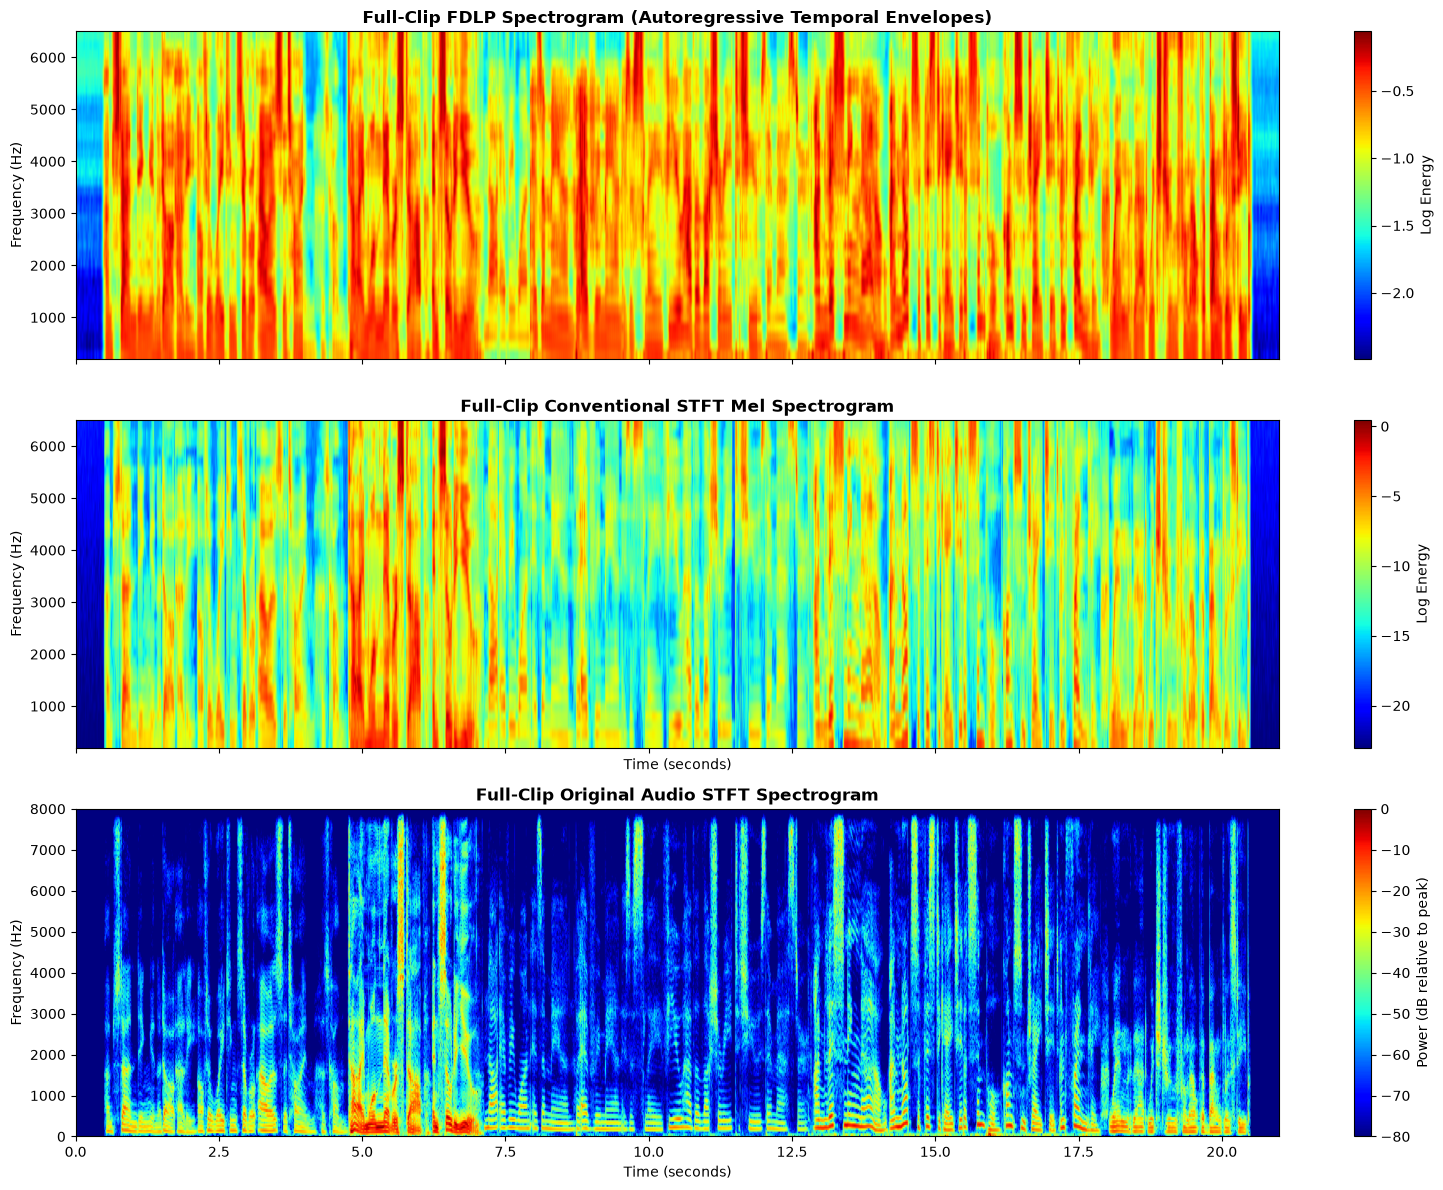

Displayed the complete 21.000-second clip (336002 samples at 16000 Hz).
FDLP spectrogram shape: (36, 2098)
Mel spectrogram shape: (36, 2101)


In [8]:
# Load the complete audio.wav clip and compute full-length spectrograms
source_audio = "audio.wav"
y, sr = sf.read(source_audio)

if y.ndim != 1:
    raise ValueError(f"Expected mono audio for this comparison; got shape {y.shape}")
clip_duration = len(y) / sr

# Retrieve the FDLP spectrogram from the batch results
fdlp_spec = batch_results[source_audio]

fdlp_spec_plot = fdlp_spec

# Compute Conventional STFT Mel Spectrogram
mfcc_ceps, aspectrum, _ = melfcc_python(y, sr=sr, nbands=fdlp_spec.shape[0])
aspectrum_plot = np.log(np.maximum(aspectrum, 0) + 1e-10)

mel_freqs = librosa.mel_frequencies(n_mels=fdlp_spec.shape[0], fmin=200, fmax=6500)

n_fft = int(0.025 * sr)
hop_length = int(0.010 * sr)
stft_power = np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop_length)) ** 2
stft_db = librosa.power_to_db(stft_power, ref=np.max)
stft_freqs = librosa.fft_frequencies(sr=sr, n_fft=n_fft)

fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

# 1. FDLP Spectrogram
axes[0].imshow(fdlp_spec_plot, aspect='auto', origin='lower', cmap='jet',
               extent=[0, clip_duration, mel_freqs[0], mel_freqs[-1]])
axes[0].set_title('Full-Clip FDLP Spectrogram (Autoregressive Temporal Envelopes)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Frequency (Hz)')
fig.colorbar(axes[0].images[0], ax=axes[0], label='Log Energy')

# 2. Conventional Mel filterbank spectrogram
axes[1].imshow(aspectrum_plot, aspect='auto', origin='lower', cmap='jet',
               extent=[0, clip_duration, mel_freqs[0], mel_freqs[-1]])
axes[1].set_title('Full-Clip Conventional STFT Mel Spectrogram', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Time (seconds)')
axes[1].set_ylabel('Frequency (Hz)')
fig.colorbar(axes[1].images[0], ax=axes[1], label='Log Energy')
axes[1].set_xlim(0, clip_duration)
# 3. Linear-frequency STFT computed directly from the original waveform
axes[2].imshow(stft_db, aspect='auto', origin='lower', cmap='jet',
               extent=[0, clip_duration, stft_freqs[0], stft_freqs[-1]],
               vmin=-80, vmax=0)
axes[2].set_title('Full-Clip Original Audio STFT Spectrogram', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Time (seconds)')
axes[2].set_ylabel('Frequency (Hz)')
fig.colorbar(axes[2].images[0], ax=axes[2], label='Power (dB relative to peak)')
axes[2].set_xlim(0, clip_duration)

fig.tight_layout()
plt.show()

print(f"Displayed the complete {clip_duration:.3f}-second clip ({len(y)} samples at {sr} Hz).")
print("FDLP spectrogram shape:", fdlp_spec_plot.shape)
print("Mel spectrogram shape:", aspectrum_plot.shape)


In [9]:
from IPython.display import Audio, FileLink, display

# Mel-band magnitudes are not directly invertible with an FFT; estimate phase with Griffin-Lim.
n_fft = int(0.025 * sr)
hop_length = int(0.010 * sr)

mel_audio = librosa.feature.inverse.mel_to_audio(
    M=np.maximum(aspectrum, 0),
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length,
    fmin=200,
    fmax=6500,
    power=2.0,
    n_iter=32,
    length=len(y),
)

# FDLP features are log(band_energy ** 0.1); undo both operations for inversion.
fdlp_power = np.exp(np.clip(fdlp_spec_plot * 10.0, -80, 80))
expected_frames = 1 + len(y) // hop_length
if fdlp_power.shape[1] < expected_frames:
    fdlp_power = np.pad(
        fdlp_power,
        ((0, 0), (0, expected_frames - fdlp_power.shape[1])),
        mode="edge",
    )
else:
    fdlp_power = fdlp_power[:, :expected_frames]
fdlp_audio = librosa.feature.inverse.mel_to_audio(
    M=fdlp_power,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length,
    fmin=200,
    fmax=6500,
    power=2.0,
    n_iter=32,
    length=len(y),
)

print("Original audio (play this first to verify notebook playback):")
display(Audio(data=y, rate=sr))

for label, samples, output_path in [
    ("Mel reconstruction", mel_audio, "mel_reconstruction.wav"),
    ("FDLP reconstruction", fdlp_audio, "fdlp_reconstruction.wav"),
]:
    samples = np.asarray(samples, dtype=np.float32)
    if samples.ndim != 1 or samples.size == 0:
        raise ValueError(f"{label} must be a non-empty mono waveform; got shape {samples.shape}")
    if not np.isfinite(samples).all():
        raise ValueError(f"{label} contains NaN or infinite samples")

    peak = np.max(np.abs(samples))
    if peak > 0:
        samples = samples / peak
    sf.write(output_path, samples, sr, subtype="PCM_16")
    print(f"{label} (saved as {output_path}; sample rate {sr} Hz):")
    display(Audio(filename=output_path))
    display(FileLink(output_path, result_html_prefix="Open/download WAV: "))


Original audio (play this first to verify notebook playback):


Mel reconstruction (saved as mel_reconstruction.wav; sample rate 16000 Hz):


c:\Users\Fardeen\Documents\College\Projects_FDLP\Antigravity_FDLP\FDLP 1\mel_reconstruction.wav

FDLP reconstruction (saved as fdlp_reconstruction.wav; sample rate 16000 Hz):


c:\Users\Fardeen\Documents\College\Projects_FDLP\Antigravity_FDLP\FDLP 1\fdlp_reconstruction.wav